In [2]:
from pathlib import Path

file_path = Path("../data/raw/women-clothing-accessories.3-class.balanced (2).csv")

with open(file_path, "r", encoding="utf-8-sig") as file:
    for i in range(5):
        print(repr(file.readline()[:300]))

'review\tsentiment\n'
'качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......\tnegative\n'
'Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.\tnegative\n'
'Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На картинке кажется приталенной на самом деле нет! Не рекомендую\tnegative\n'
'товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания\tnegative\n'


In [ ]:

import pandas as pd
from pathlib import Path

# Find project folder
project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Dataset path
file_path = (
    project_dir
    / "data"
    / "raw"
    / "women-clothing-accessories.3-class.balanced (2).csv"
)

# Load dataset with tab separator
df = pd.read_csv(file_path, sep="\t")

# Display dataset information
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\nTotal reviews:", len(df))

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five reviews:")
display(df.head())


Dataset shape: (90000, 2)
Columns: ['review', 'sentiment']

Total reviews: 90000

Sentiment distribution:
sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64

First five reviews:


,review,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [ ]:

import re

# Remove missing values
df = df.dropna(subset=["review", "sentiment"]).copy()

# Clean Russian text
def clean_text(text):
    text = str(text).lower()
    text = text.replace("ё", "е")
    text = re.sub(r"[^а-я\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_review"] = df["review"].apply(clean_text)

# Remove empty reviews
df = df[df["clean_review"] != ""].copy()

print("Reviews after cleaning:", len(df))

display(
    df[["review", "clean_review", "sentiment"]].head()
)


Reviews after cleaning: 88738


,review,clean_review,sentiment
0,качество плохое пошив ужасный (горловина напер...,качество плохое пошив ужасный горловина напере...,negative
1,"Товар отдали другому человеку, я не получила п...",товар отдали другому человеку я не получила по...,negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",ужасная синтетика тонкая ничего общего с предс...,negative
3,"товар не пришел, продавец продлил защиту без м...",товар не пришел продавец продлил защиту без мо...,negative
4,"Кофточка голая синтетика, носить не возможно.",кофточка голая синтетика носить не возможно,negative


sentiment
neautral    29614
negative    29584
positive    29540
Name: count, dtype: int64


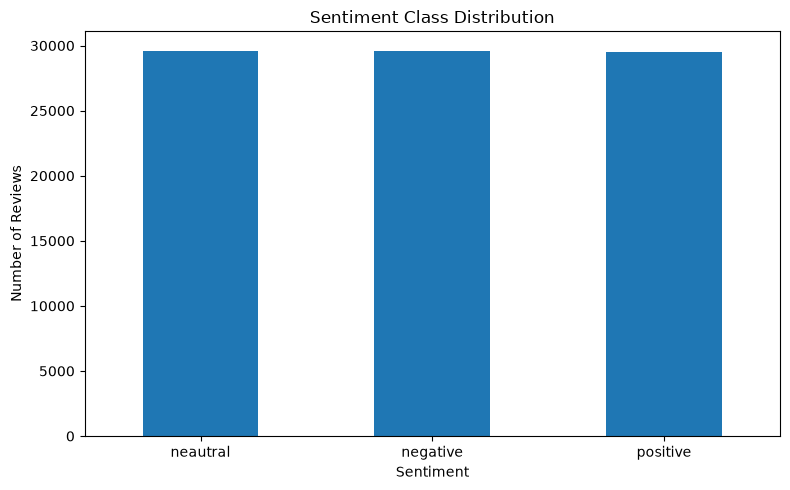

In [ ]:

import matplotlib.pyplot as plt

class_counts = df["sentiment"].value_counts()

print(class_counts)

plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Dataset Exploration

The dataset contains Russian-language product reviews labeled by sentiment.

The class distribution was examined to identify the number of positive, negative, and neutral reviews.

Text preprocessing included lowercase conversion, removal of punctuation and digits, normalization of Russian characters, and removal of extra spaces.

In [ ]:

from sklearn.model_selection import train_test_split

X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Classes:", sorted(y.unique()))


Training reviews: 70990
Testing reviews: 17748
Classes: ['neautral', 'negative', 'positive']


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

models = {
    "Count + Naive Bayes": Pipeline([
        ("vectorizer", CountVectorizer(max_features=10000)),
        ("classifier", MultinomialNB())
    ]),
    "TF-IDF + Naive Bayes": Pipeline([
        ("vectorizer", TfidfVectorizer(max_features=10000)),
        ("classifier", MultinomialNB())
    ]),
    "Count + Logistic Regression": Pipeline([
        ("vectorizer", CountVectorizer(max_features=10000)),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),
    "TF-IDF + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(max_features=10000)),
        ("classifier", LogisticRegression(max_iter=1000))
    ])
}

print("Four pipelines created successfully!")


Four pipelines created successfully!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

results = []

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


Training: Count + Naive Bayes
Training: TF-IDF + Naive Bayes
Training: Count + Logistic Regression
Training: TF-IDF + Logistic Regression


,Model,Accuracy,Precision,Recall,F1
0,Count + Naive Bayes,0.7185,0.7265,0.7186,0.7201
1,TF-IDF + Naive Bayes,0.7208,0.7306,0.7208,0.7227
2,Count + Logistic Regression,0.7343,0.7359,0.7344,0.7350
3,TF-IDF + Logistic Regression,0.7401,0.7428,0.7402,0.7414


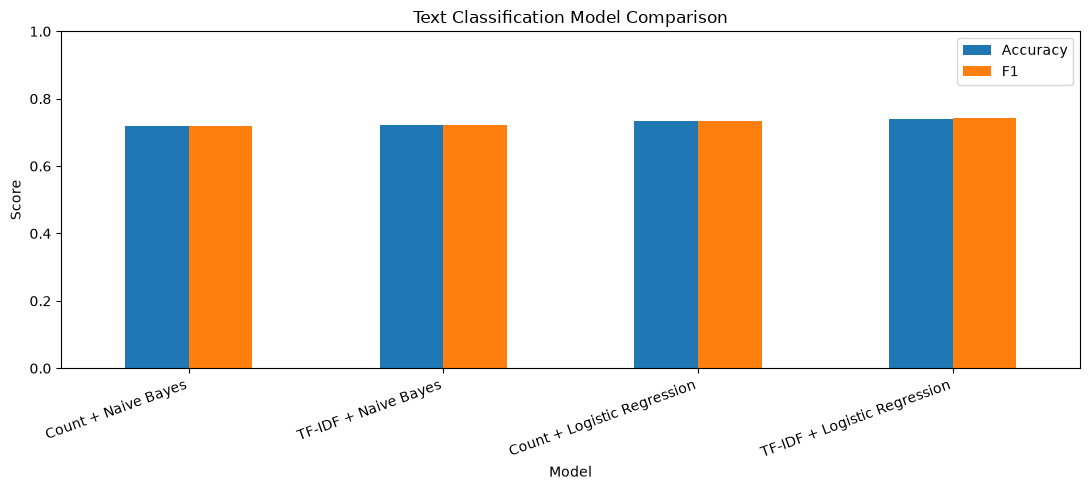

In [ ]:

results_df.plot(
    x="Model",
    y=["Accuracy", "F1"],
    kind="bar",
    figsize=(11, 5)
)

plt.title("Text Classification Model Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


## Model Comparison

Two text vectorization techniques were evaluated: CountVectorizer and TF-IDF.

Two classifiers were trained: Multinomial Naive Bayes and Logistic Regression.

All four pipelines used the same training and testing split to ensure a consistent comparison.

The models were evaluated using accuracy, macro precision, macro recall, and macro F1-score.

Macro F1-score was used to compare performance across all sentiment classes.

Best model: TF-IDF + Logistic Regression

Classification report:
              precision    recall  f1-score   support

    neautral       0.62      0.65      0.64      5923
    negative       0.73      0.71      0.72      5917
    positive       0.87      0.85      0.86      5908

    accuracy                           0.74     17748
   macro avg       0.74      0.74      0.74     17748
weighted avg       0.74      0.74      0.74     17748



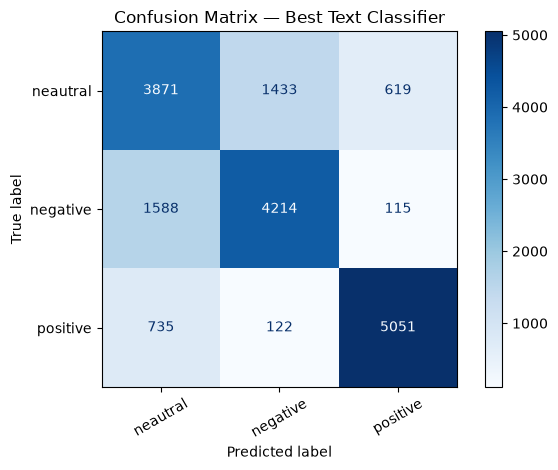

In [ ]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

best_name = results_df.sort_values(
    "F1", ascending=False
).iloc[0]["Model"]

best_model = models[best_name]
best_predictions = best_model.predict(X_test)

print("Best model:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    cmap="Blues",
    xticks_rotation=30
)

plt.title("Confusion Matrix — Best Text Classifier")
plt.tight_layout()
plt.show()


In [ ]:

error_analysis = pd.DataFrame({
    "Review": df.loc[X_test.index, "review"].values,
    "Actual": y_test.values,
    "Predicted": best_predictions
})

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Misclassified reviews:", len(errors))

display(errors.head(10))


Misclassified reviews: 4612


,Review,Actual,Predicted
3,"Платье неплохое, только горох не белый а серый...",neautral,positive
4,"Заказываю 2 раз и товар не приходит ,деньги ве...",negative,positive
5,"платье в принципе неплое, мягкое(синтетика), б...",neautral,positive
7,"Товар пришёл быстро, хороший продавец, товар о...",neautral,positive
8,ужасная ужасная ткань. очень не приятно носить...,neautral,negative
15,маломерная модель. \r\r\nРасхождение разреза ...,negative,neautral
19,"хороший. Немного странный, непонятно где перед...",positive,neautral
20,"кардиган красивый!Но,швы кривые ужас\r\nно! на...",positive,neautral
21,"Куртка замечательная, но размер напрочь не соо...",neautral,negative
22,качество материала не очень...,negative,neautral


## Final Conclusions

Practical Work 6 focused on sentiment classification of Russian-language product reviews.

The dataset was cleaned using language-specific text preprocessing techniques.

CountVectorizer and TF-IDF were used to transform text into numerical features.

Multinomial Naive Bayes and Logistic Regression were evaluated using the same train/test split.

The classification models were compared using accuracy, precision, recall, and macro F1-score.

A confusion matrix and misclassified review examples were used to examine prediction errors.

The experiment demonstrates how traditional machine learning algorithms can classify Russian-language text and how vectorization methods influence classification performance.